# 62 · Bản đồ đặc trưng từng stage — **đặc trưng hình thành ở đâu, nên can thiệp ở đâu**

## Hai phần

**Phần nhìn** — lưới bản đồ kích hoạt từng kênh ở cả 4 stage, đúng kiểu slide: mỗi ô là một kênh,
chuẩn hoá riêng, `viridis`. Nhìn được stage 1 bắt cạnh/kết cấu, stage 4 bắt vùng trừu tượng.

**Phần đo** — vì mắt không phân định được *"tầng nào đáng can thiệp"*. Ba số cho mỗi stage:

```
kenh chet     % kenh gan nhu khong bao gio bat  -> tang co nhieu kenh chet = du sac de sua
hang hieu dung  so chieu THAT SU duoc dung       -> thap = kenh du thua, can thiep re
1 - CKA       fine-tune da doi tang do bao nhieu -> CHINH mo hinh da chon sua o dau
```

Số thứ ba là câu trả lời trực tiếp nhất: so đặc trưng của backbone **ImageNet gốc** với backbone
**đã fine-tune trên CXR-LT**, từng tầng. Tầng nào `CKA` tụt mạnh là tầng mà việc học nhiệm vụ đã
buộc phải viết lại — đó là nơi đặc trưng riêng cho bài toán thật sự hình thành.

## Không huấn luyện gì

Chỉ forward. `~3 phút`, và chỉ cần **~256 ảnh** (một tar), không phải 377k.

## Vì sao KHÔNG dùng deconvnet gốc Zeiler–Fergus

Bài 2014 chuyển vị chính trọng số conv và dùng switch của max-pool để unpool. ConvNeXt **không có
max-pool** (downsample bằng conv stride 2), dùng **GELU** thay ReLU, có LayerNorm — cả ba thứ phép
nghịch đảo đó dựa vào. Ở đây nhìn **thẳng** bản đồ kích hoạt: không cần giả định nghịch đảo nào.


## C0 · Config + tự nạp ảnh (chỉ nạp đủ dùng)

In [1]:
import os, json, math, time, glob, shutil, tarfile
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib; import matplotlib.pyplot as plt
try:
    import timm
except ImportError:
    import subprocess, sys as _s
    subprocess.run([_s.executable, '-m', 'pip', 'install', '-q', 'timm']); import timm
try:
    from google.colab import drive
    drive.mount('/content/drive'); DATA_DIR = '/content/drive/MyDrive/MIMIC_CXR/planB_out'
except Exception:
    DATA_DIR = os.environ.get('CXRLT_DATA', '')
    assert DATA_DIR, 'khong phai Colab va chua dat CXRLT_DATA -> gan thang duong dan `planB_out`'
OUT_DIR = os.path.join(DATA_DIR, 'cxrlt_2024'); EMB_DIR = os.path.join(OUT_DIR, 'embeddings')

RES_LOC = '/content/nb62'; os.makedirs(RES_LOC, exist_ok=True)     # NOI GHI CHINH
RES62 = os.path.join(OUT_DIR, 'stage4_nb62')
def ensure_res():
    try: os.makedirs(RES62, exist_ok=True)
    except Exception: pass
    return RES62
PUT_FAIL = []
def put(name, fn):
    lp = os.path.join(RES_LOC, name); fn(lp); dp = os.path.join(RES62, name)
    try:
        ensure_res(); shutil.copy(lp, dp)
        if os.path.getsize(dp) != os.path.getsize(lp): raise OSError('kich thuoc lech')
    except Exception as e:
        PUT_FAIL.append(name); print(f'  !! sao {name} len Drive THAT BAI ({type(e).__name__})')
    return lp
ensure_res()

MODEL = 'convnextv2_nano.fcmae_ft_in22k_in1k'
P_FT  = os.path.join(OUT_DIR, 'stage4_nb41f', 'r2', 'cnn_arch_s42.pt')   # backbone da fine-tune
P_PC  = os.path.join(OUT_DIR, 'stage4_nb41c', 'convnextv2_padchest.pt')
LOCAL = '/content/cxrlt_518'
READY_X = os.path.join(OUT_DIR, 'cxrlt_518_ready')
SIZE, SEED = 518, 42
N_STAT, N_VIZ = 256, 3           # N_STAT anh cho phan DO, N_VIZ anh cho phan NHIN
NCH_SHOW = 64                    # so kenh ve moi stage (luoi 8x8)
STAGES = (0, 1, 2, 3)

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = torch.bfloat16 if (dev == 'cuda' and torch.cuda.is_bf16_supported()) else torch.float32
print(f'thiet bi: {dev} | AMP {AMP}')

ORDER = pd.read_parquet(os.path.join(EMB_DIR, 'emb_index.parquet'))
os.makedirs(LOCAL, exist_ok=True)
_tr = set(ORDER[ORDER.split == 'train'].dicom_id.to_numpy()); CAN = N_STAT + N_VIZ
def _pool_now():
    return np.array(sorted(set(f[:-4] for f in os.listdir(LOCAL) if f.endswith('.jpg')) & _tr))
_pool = _pool_now()
print(f'anh train dang co: {len(_pool):,} / can {CAN:,}', flush=True)
if len(_pool) < CAN:
    assert os.path.isdir(READY_X), f'khong thay kho {READY_X} -> chay C3-bis cua 41c'
    _tars = sorted(x for x in os.listdir(READY_X) if x.endswith('.tar'))
    assert _tars, f'kho {READY_X} khong co tar nao'
    for _i, f in enumerate(_tars):
        src, tmp = os.path.join(READY_X, f), os.path.join('/content', f)
        try:
            shutil.copy(src, tmp)          # copy TRUOC — khong mo tar thang tren mount FUSE
            assert os.path.getsize(tmp) == os.path.getsize(src), 'copy NGAN tu Drive'
            with tarfile.open(tmp) as tar: tar.extractall(LOCAL, filter='data')
        except Exception as e:
            print(f'  {f} HONG ({type(e).__name__}) -> bo qua')
        finally:
            if os.path.exists(tmp): os.remove(tmp)
        _pool = _pool_now(); print(f'  tar {_i+1} -> {len(_pool):,}/{CAN:,}', flush=True)
        if len(_pool) >= CAN: break
assert len(_pool) >= CAN, f'chi co {len(_pool):,}/{CAN:,} anh -> ha N_STAT o C0'
_rs = np.random.default_rng(SEED); _pk = _rs.choice(len(_pool), CAN, replace=False)
IDS_ST, IDS_VZ = _pool[_pk[:N_STAT]], _pool[_pk[N_STAT:]]
print(f'do: {len(IDS_ST)} anh | nhin: {len(IDS_VZ)} anh')

Mounted at /content/drive
thiet bi: cuda | AMP torch.bfloat16
anh train dang co: 0 / can 259
  tar 1 -> 794/259
do: 256 anh | nhin: 3 anh


## C1 · Encoder — lấy **cả 4 stage**, và cổng tái lập `forward_features`

In [2]:
_m0 = timm.create_model(MODEL, pretrained=True, num_classes=0, in_chans=1)
_cfg = timm.data.resolve_model_data_config(_m0)
MU, SD = float(np.mean(_cfg['mean'])), float(np.mean(_cfg['std']))
_IN_SD = {k: v.clone() for k, v in _m0.state_dict().items()}; del _m0

def build_encoder(which):
    bb = timm.create_model(MODEL, pretrained=(which == 'imagenet'), num_classes=0, in_chans=1)
    if which == 'imagenet': return bb.eval(), 'ImageNet goc'
    src = P_FT if (which == 'cxrlt' and os.path.exists(P_FT)) else P_PC
    assert os.path.exists(src), f'khong thay {src} -> chay 41f (hoac 41c) truoc'
    ck = torch.load(src, map_location='cpu', weights_only=False)
    sd = ck['bb'] if 'bb' in ck else {k: v for k, v in ck['sd'].items() if not k.startswith('head.')}
    miss = bb.load_state_dict(sd, strict=False)
    bad = [k for k in miss.missing_keys if not k.startswith('head.')]
    assert not bad, f'thieu khoa khi nap {src}: {bad[:5]}'
    with torch.no_grad():
        d = max((_IN_SD[k] - v).abs().max().item() for k, v in bb.state_dict().items()
                if k in _IN_SD)
    assert d > 1e-4, f'trong so GIONG HET ImageNet (lech {d:.1e}) -> nap that bai'
    return bb.eval(), ('CXR-LT fine-tune' if src == P_FT else 'PadChest') + f' (lech IN {d:.2f})'

def taps(bb, x):
    '''Dau ra CA BON stage. Duong di nay phai TAI LAP forward_features, neu khong ta dang
       nhin mot mang KHAC voi mang dang dung.'''
    o = []; x = bb.stem(x)
    for st in bb.stages: x = st(x); o.append(x)
    return o

_bb, _ = build_encoder('imagenet'); _bb = _bb.to(dev)
with torch.no_grad():
    _x = torch.zeros(2, 1, SIZE, SIZE, device=dev)
    _f = taps(_bb, _x); _d = float((_f[-1] - _bb.forward_features(_x)).abs().max())
assert _d < 1e-3, f'taps() lech forward_features {_d:.2e} -> cat SAI stage. DUNG.'
SH = [tuple(t.shape) for t in _f]
_chlast = SH[-1][-1] != SH[-1][-2]
CH = [s[-1] if _chlast else s[1] for s in SH]
GRID = [(s[1], s[2]) if _chlast else (s[2], s[3]) for s in SH]
def nchw(t): return t.permute(0, 3, 1, 2).contiguous() if _chlast else t
print(f'cong 1: taps() tai lap forward_features toi {_d:.1e} | '
      f'{"channels-LAST" if _chlast else "channels-FIRST"}')
print(f'\n{"":8}{"luoi":>9}{"kenh":>7}{"stride":>8}{"o (mm)":>9}')
for k in STAGES:
    st = SIZE // GRID[k][0]
    print(f'  stage{k+1}{GRID[k][0]:>7}x{GRID[k][1]:<2}{CH[k]:>6}{st:>8}{350*st//SIZE:>8}mm')
del _bb; torch.cuda.empty_cache()

from PIL import Image
def load(ids):
    a = np.stack([np.asarray(Image.open(os.path.join(LOCAL, f'{d}.jpg')).convert('L'),
                             dtype='uint8') for d in ids]).astype('float32') / 255.0
    return torch.from_numpy(a).unsqueeze(1), a

@torch.no_grad()
def feats(bb, x, bs=16):
    '''Tra ve list 4 tensor [N, C, H, W] tren CPU.'''
    out = None
    for i in range(0, len(x), bs):
        xb = ((x[i:i+bs] - MU) / SD).to(dev)
        with torch.autocast(dev, dtype=AMP, enabled=(dev == 'cuda')):
            fs = [nchw(t).float().cpu() for t in taps(bb, xb)]
        out = fs if out is None else [torch.cat([a, b]) for a, b in zip(out, fs)]
    return out

model.safetensors: reconstructing file:   0%|          |  0.00B / 62.5MB            

model.safetensors: downloading bytes:           |  0.00B            

cong 1: taps() tai lap forward_features toi 0.0e+00 | channels-FIRST

             luoi   kenh  stride   o (mm)
  stage1    129x129    80       4       2mm
  stage2     64x64   160       8       5mm
  stage3     32x32   320      16      10mm
  stage4     16x16   640      32      21mm


## C2 · **Hình chính** — lưới bản đồ kích hoạt từng kênh, cả 4 stage

Mỗi ô là **một kênh**, chuẩn hoá riêng theo min–max của chính nó (đúng cách slide vẽ). Kênh được
xếp theo **độ biến thiên không gian giảm dần** — kênh đầu bảng là kênh "nói" nhiều nhất về ảnh
này, thay vì thứ tự tuỳ tiện.

  da ghi kenh_imagenet.png


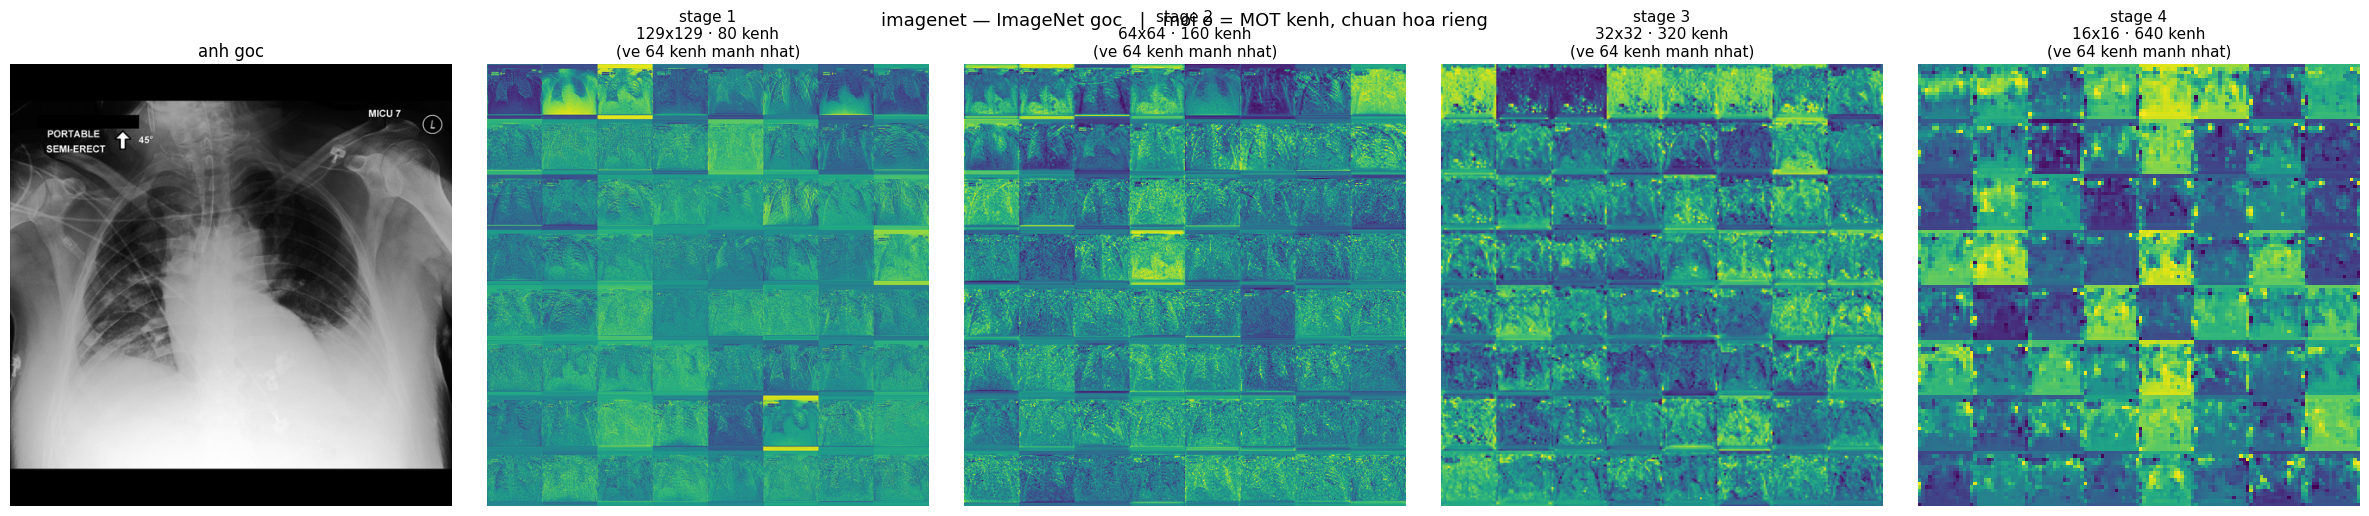

  da ghi kenh_cxrlt.png


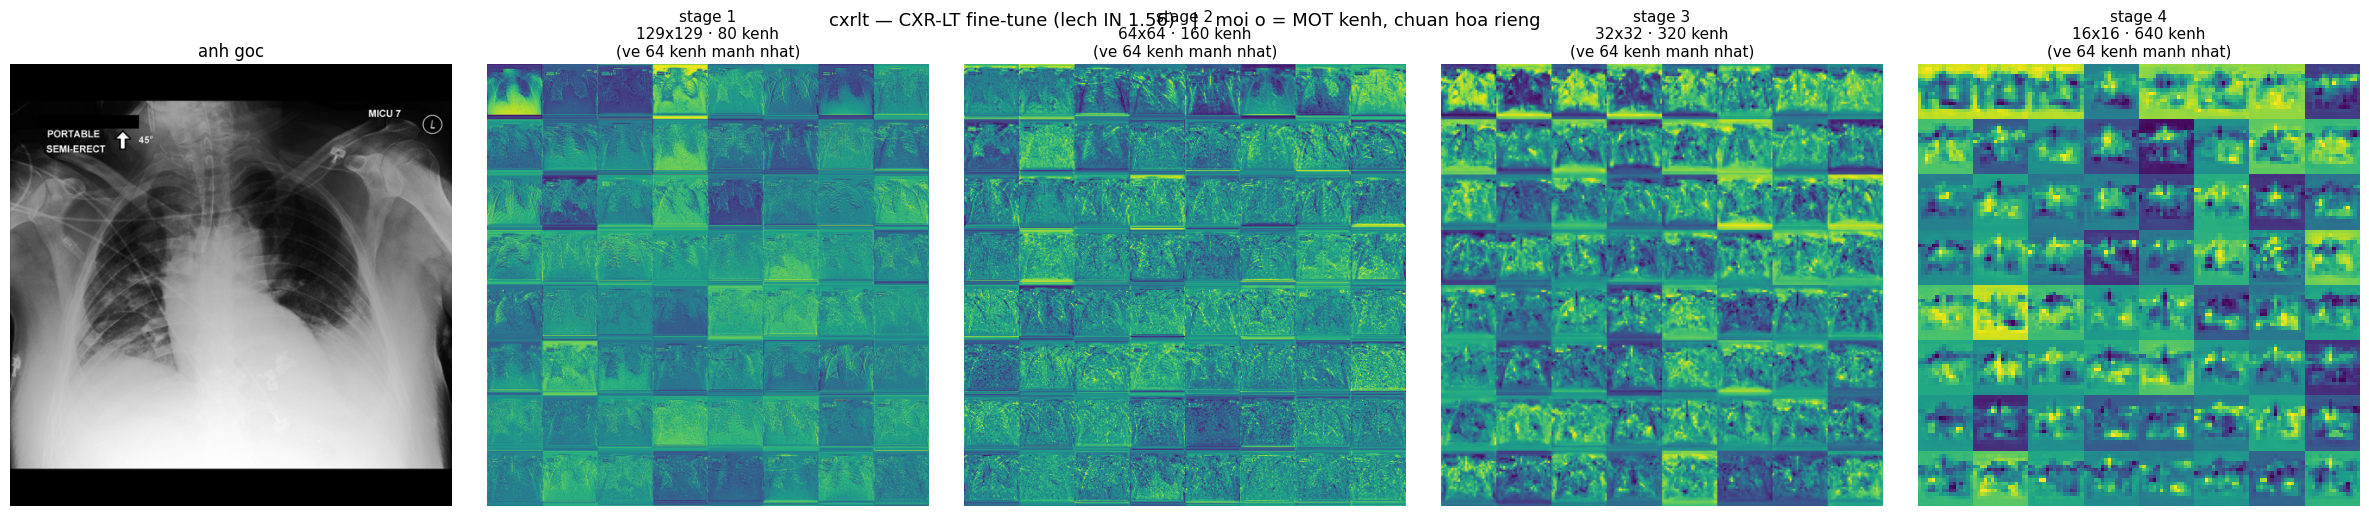

In [3]:
def luoi_kenh(F_, n=NCH_SHOW, cmap='viridis'):
    '''F_ : [C,H,W] -> anh luoi ke o, moi o mot kenh da chuan hoa rieng.'''
    f = F_.numpy(); order = np.argsort(-f.std(axis=(1, 2)))[:n]     # kenh "noi" nhieu nhat truoc
    side = int(math.ceil(math.sqrt(len(order))))
    H, W = f.shape[1], f.shape[2]
    canvas = np.zeros((side*H, side*W), 'float32')
    for i, c in enumerate(order):
        a = f[c]; lo, hi = a.min(), a.max()
        a = (a - lo) / (hi - lo + 1e-8)
        r, q = divmod(i, side); canvas[r*H:(r+1)*H, q*W:(q+1)*W] = a
    return canvas, side, len(order)

def ve_stage(which, i_img=0, fname=None):
    bb, tag = build_encoder(which); bb = bb.to(dev)
    x, raw = load(IDS_VZ); fs = feats(bb, x)
    fig, ax = plt.subplots(1, 5, figsize=(24, 5.2))
    ax[0].imshow(raw[i_img], cmap='gray'); ax[0].set_title('anh goc', fontsize=12)
    ax[0].axis('off')
    for j, k in enumerate(STAGES):
        cv, side, nch = luoi_kenh(fs[k][i_img])
        ax[j+1].imshow(cv, cmap='viridis'); ax[j+1].axis('off')
        ax[j+1].set_title(f'stage {k+1}\n{GRID[k][0]}x{GRID[k][1]} · {CH[k]} kenh\n'
                          f'(ve {nch} kenh manh nhat)', fontsize=11)
    fig.suptitle(f'{which} — {tag}   |   moi o = MOT kenh, chuan hoa rieng', fontsize=13)
    fig.tight_layout()
    if fname:
        put(fname, lambda q: fig.savefig(q, dpi=110, bbox_inches='tight'))
        print(f'  da ghi {fname}')
    plt.show()
    del bb; torch.cuda.empty_cache()
    return fs, raw

FS = {}
for which in ('imagenet', 'cxrlt'):
    FS[which] = ve_stage(which, 0, f'kenh_{which}.png')

## C3 · Phóng to **vài kênh** ở mỗi stage, phủ lên ảnh gốc

Lưới ở C2 cho thấy *hình dạng* đặc trưng; hình này cho thấy chúng **rơi vào đâu trên lồng ngực** —
cần thiết để nói "stage này bắt vùng rốn phổi" thay vì "stage này trông có cấu trúc".

  da ghi phu_imagenet.png


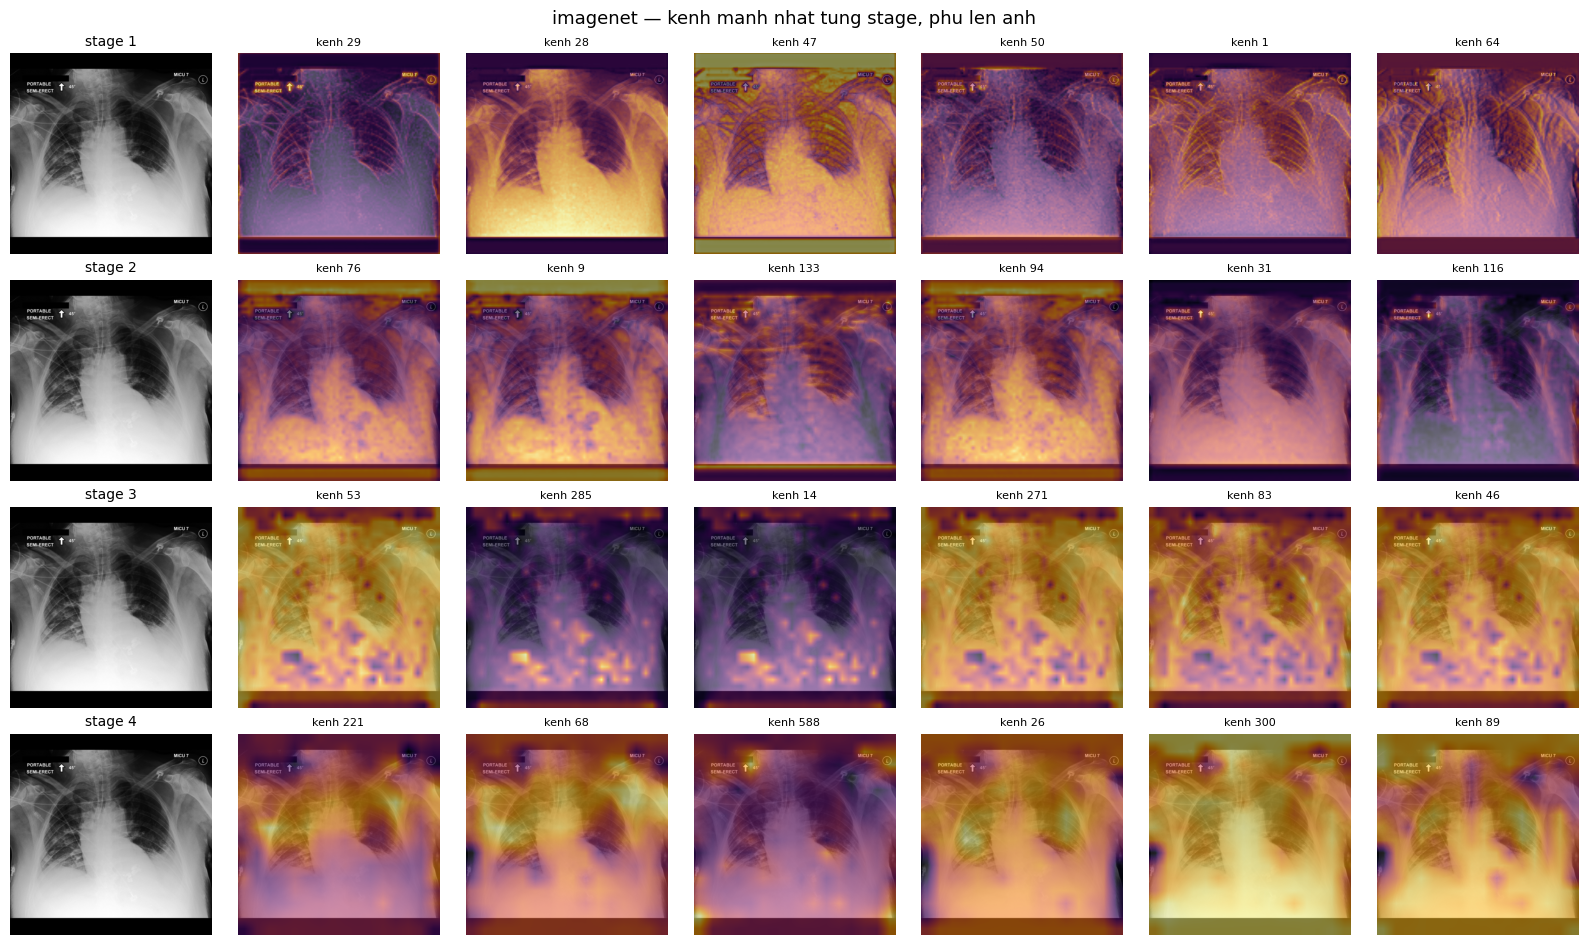

  da ghi phu_cxrlt.png


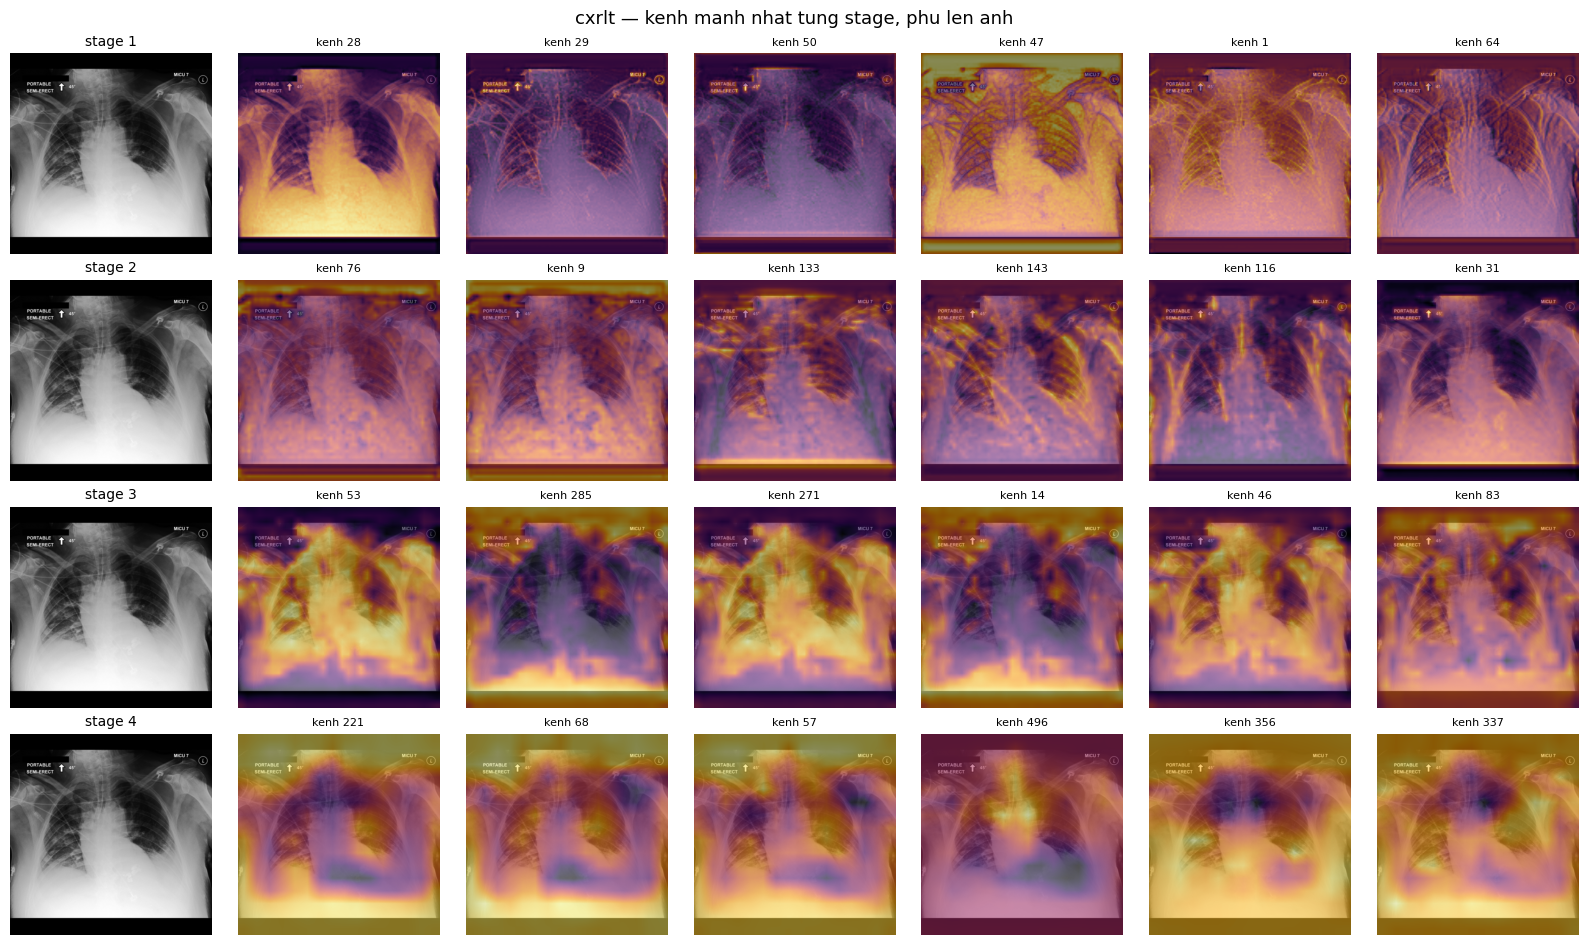

In [4]:
def ve_phu(which, i_img=0, ncol=6, fname=None):
    fs, raw = FS[which]; img = raw[i_img]
    fig, ax = plt.subplots(len(STAGES), ncol+1, figsize=(2.3*(ncol+1), 2.4*len(STAGES)))
    for r, k in enumerate(STAGES):
        f = fs[k][i_img].numpy(); order = np.argsort(-f.std(axis=(1, 2)))[:ncol]
        ax[r, 0].imshow(img, cmap='gray'); ax[r, 0].axis('off')
        ax[r, 0].set_title(f'stage {k+1}', fontsize=10)
        for c, ch in enumerate(order):
            a = f[ch]; a = (a - a.min()) / (a.max() - a.min() + 1e-8)
            up = F.interpolate(torch.tensor(a)[None, None], size=img.shape,
                               mode='bilinear', align_corners=False)[0, 0].numpy()
            ax[r, c+1].imshow(img, cmap='gray')
            ax[r, c+1].imshow(up, cmap='inferno', alpha=0.55)
            ax[r, c+1].axis('off'); ax[r, c+1].set_title(f'kenh {ch}', fontsize=8)
    fig.suptitle(f'{which} — kenh manh nhat tung stage, phu len anh', fontsize=13)
    fig.tight_layout()
    if fname:
        put(fname, lambda q: fig.savefig(q, dpi=110, bbox_inches='tight'))
        print(f'  da ghi {fname}')
    plt.show()

for which in FS: ve_phu(which, 0, fname=f'phu_{which}.png')

## C4 · **Đo** — tầng nào đáng can thiệp

Mắt không phân định được điều này, nên đo ba thứ trên `N_STAT` ảnh:

```
kenh chet %     kenh co do lech chuan < 1% muc trung binh cua tang do
hang hieu dung  (sum λ)^2 / sum λ^2 tren hiep phuong sai kenh — so chieu THAT SU dung
1 - CKA         CKA tuyen tinh giua ImageNet va ban fine-tune, tung tang
```

`1 − CKA` là thứ trả lời thẳng câu hỏi: **chính mô hình đã chọn viết lại ở tầng nào** khi phải học
40 nhãn. Tầng đó là nơi đặc trưng riêng cho bài toán hình thành.

In [5]:
def cka(X, Y):
    '''CKA tuyen tinh. X,Y: [n_mau, n_kenh], moi hang la mot vi tri khong gian cua mot anh.'''
    X = X - X.mean(0, keepdims=True); Y = Y - Y.mean(0, keepdims=True)
    xy = np.linalg.norm(Y.T @ X, 'fro') ** 2
    xx = np.linalg.norm(X.T @ X, 'fro'); yy = np.linalg.norm(Y.T @ Y, 'fro')
    return float(xy / (xx * yy + 1e-12))
_r = np.random.default_rng(0); _t = _r.random((500, 30)).astype('float32')
assert abs(cka(_t, _t) - 1.0) < 1e-5, 'cka(X,X) phai bang 1'
_p = _r.permutation(30)
assert abs(cka(_t, _t[:, _p]) - 1.0) < 1e-5, 'CKA phai BAT BIEN voi hoan vi kenh'
print('cong 2: CKA(X,X)=1 va bat bien hoan vi kenh')

x_st, _ = load(IDS_ST)
STAT = {}
for which in ('imagenet', 'cxrlt'):
    bb, tag = build_encoder(which); bb = bb.to(dev)
    fs = feats(bb, x_st)
    S = {}
    for k in STAGES:
        f = fs[k]                                        # [N,C,H,W]
        sd_ch = f.std(dim=(0, 2, 3)).numpy()
        chet = float((sd_ch < 0.01 * sd_ch.mean()).mean())
        M = f.permute(0, 2, 3, 1).reshape(-1, f.shape[1]).numpy()
        idx = np.random.default_rng(1).choice(len(M), min(4000, len(M)), replace=False)
        M = M[idx]
        def _hang(A):
            Ac = A - A.mean(0, keepdims=True)
            ev = np.linalg.eigvalsh(np.cov(Ac, rowvar=False) + 1e-8*np.eye(A.shape[1]))
            return float(np.clip(ev, 0, None).sum()**2
                         / (np.sum(np.clip(ev, 0, None)**2) + 1e-12))
        # Ban CHUAN HOA: z-score TUNG KENH. ConvNeXt co hien tuong "massive activation" —
        # mot vai kenh bien do khong lo lam hiep phuong sai bi CHUNG chi phoi, keo hang hieu
        # dung ve ~1 va lam CKA chi con do DUNG huong do. Hai ban canh nhau moi phan biet duoc
        # "dac trung that su thap chieu" voi "mot kenh troi che het".
        Mz = (M - M.mean(0, keepdims=True)) / (M.std(0, keepdims=True) + 1e-8)
        S[k] = dict(chet=chet, hang=_hang(M), hang_z=_hang(Mz),
                    n_kenh=int(f.shape[1]), M=M, Mz=Mz)
    STAT[which] = dict(tag=tag, S=S)
    del bb, fs; torch.cuda.empty_cache()

print(f'\n{"stage":<8}{"kenh":>6}'
      + ''.join(f'{w+" chet":>12}{w+" hang":>12}{w+" hang_z":>13}' for w in STAT))
for k in STAGES:
    row = f'  stage{k+1:<2}{STAT["imagenet"]["S"][k]["n_kenh"]:>6}'
    for w in STAT:
        s = STAT[w]['S'][k]
        row += f'{s["chet"]*100:>11.1f}%{s["hang"]:>12.1f}{s["hang_z"]:>13.1f}'
    print(row)
print('  hang   = tren dac trung THO   (bi kenh bien do lon chi phoi)')
print('  hang_z = sau khi z-score tung kenh — hang THAT SU cua khong gian dac trung')

if len(STAT) == 2:
    print(f'\n{"stage":<8}{"CKA tho":>10}{"CKA z":>9}{"1-CKA z":>10}   fine-tune viet lai (ban z)')
    CK, CKZ = {}, {}
    for k in STAGES:
        CK[k] = cka(STAT['imagenet']['S'][k]['M'], STAT['cxrlt']['S'][k]['M'])
        CKZ[k] = cka(STAT['imagenet']['S'][k]['Mz'], STAT['cxrlt']['S'][k]['Mz'])
        bar = '#' * int(round(max(0.0, 1-CKZ[k]) * 55))
        print(f'  stage{k+1:<2}{CK[k]:>10.4f}{CKZ[k]:>9.4f}{1-CKZ[k]:>10.4f}   {bar}')
    _kmax = max(STAGES, key=lambda k: 1 - CKZ[k])
    print(f'\n  -> DOC BAN z: tang bi viet lai NHIEU NHAT la stage {_kmax+1} '
          f'(1-CKA_z = {1-CKZ[_kmax]:.4f})')
    print('     Day la noi dac trung RIENG cho 40 nhan hinh thanh -> can thiep o day co don bay.')
    _lech = max(abs(CK[k] - CKZ[k]) for k in STAGES)
    if _lech > 0.15:
        print(f'\n  !! CKA tho va CKA z lech toi {_lech:.2f} -> ban THO bi mot vai kenh bien do lon')
        print('     chi phoi (massive activation). CHI doc ban z; bo ban tho di.')
    else:
        print(f'\n  hai ban khop (lech toi da {_lech:.2f}) -> ket luan khong phu thuoc chuan hoa.')
    _sum = dict(cka_tho={f'stage{k+1}': CK[k] for k in STAGES},
                cka_z={f'stage{k+1}': CKZ[k] for k in STAGES},
                thongke={w: {f'stage{k+1}': dict(chet=STAT[w]['S'][k]['chet'],
                                                 hang=STAT[w]['S'][k]['hang'],
                                                 hang_z=STAT[w]['S'][k]['hang_z'])
                             for k in STAGES} for w in STAT})
    put('feature_stats.json', lambda q: json.dump(_sum, open(q, 'w'), indent=1))
    print('\nda ghi: kenh_*.png, phu_*.png, feature_stats.json')
if PUT_FAIL: print(f'!! {len(PUT_FAIL)} file khong len duoc Drive, ban local o {RES_LOC}')

cong 2: CKA(X,X)=1 va bat bien hoan vi kenh

stage     kenhimagenet chetimagenet hangimagenet hang_z  cxrlt chet  cxrlt hang cxrlt hang_z
  stage1     80        0.0%         9.9         20.7        0.0%        10.4         19.2
  stage2    160        0.0%         1.7         42.9        0.0%         2.0         36.3
  stage3    320        0.0%         1.1         37.7        0.0%         1.1         28.0
  stage4    640        0.0%        25.1         32.9        0.0%        22.7         44.5
  hang   = tren dac trung THO   (bi kenh bien do lon chi phoi)
  hang_z = sau khi z-score tung kenh — hang THAT SU cua khong gian dac trung

stage      CKA tho    CKA z   1-CKA z   fine-tune viet lai (ban z)
  stage1     0.7759   0.7270    0.2730   ###############
  stage2     0.4477   0.6481    0.3519   ###################
  stage3     0.1195   0.3706    0.6294   ###################################
  stage4     0.1267   0.1470    0.8530   ###############################################

  -> DOC 

## C5 · Neural collapse — không gian đặc trưng có co về `C−1` chiều không

`C4` đo trên **từng vị trí không gian**; lý thuyết neural collapse (Papyan–Han–Donoho) nói về
**từng ảnh** sau global-pool. Nên con số `hang_z(stage4) = 44.5 ≈ 40 nhãn` ở `C4` mới chỉ là gợi ý,
chưa phải phép thử.

```
neural collapse du doan:  hang cua dac trung TUNG ANH  ->  C - 1
CXR-LT   C = 40    -> 39
ImageNet C = 1000  -> 999    (mo hinh goc — DOI CHUNG)
```

**Vì sao đáng quan tâm:** nếu đúng, nó nối **ba** kết quả rời rạc thành một lời giải thích duy nhất
— `59` thấy classifier **đã hội tụ**, `C4` thấy stage 4 chỉ dùng ~5% số chiều, và tail không lên dù
thử đủ mọi cách. Cả ba đều là hệ quả của *"biểu diễn đã co về đúng số chiều tối thiểu mà 40 nhãn
cần, không giữ lại gì thêm cho nhãn hiếm"*.

**Ba caveat, nêu TRƯỚC để không tự lừa:**

```
1. Neural collapse ly thuyet dat cho DON NHAN. Ta DA NHAN 40 -> chi la loai suy.
2. Hang bi CHAN TREN boi min(so anh, so kenh) — in kem can tren de biet co cham tran khong.
3. Do o stage 4 cua BACKBONE, chua phai tang ap chot that su (ML-Decoder con o sau).
```

Cell tự chủ: tự nạp thêm ảnh nếu thiếu, không đụng gì tới C0–C4. `~2 phút`.


In [ ]:
# ---- C5: hang cua dac trung TUNG ANH (da global-pool) ----
N_NC = 1024                      # can >> hang ky vong (39) de khong cham tran
_pool_nc = _pool_now()
if len(_pool_nc) < N_NC:
    for f in sorted(x for x in os.listdir(READY_X) if x.endswith('.tar')):
        if len(_pool_nc) >= N_NC: break
        if os.path.exists(os.path.join(LOCAL, '_seen_' + f)): continue
        src, tmp = os.path.join(READY_X, f), os.path.join('/content', f)
        try:
            shutil.copy(src, tmp)          # copy TRUOC — khong mo tar tren mount FUSE
            assert os.path.getsize(tmp) == os.path.getsize(src), 'copy NGAN tu Drive'
            with tarfile.open(tmp) as tar: tar.extractall(LOCAL, filter='data')
            open(os.path.join(LOCAL, '_seen_' + f), 'w').close()
        except Exception as e:
            print(f'  {f} HONG ({type(e).__name__}) -> bo qua')
        finally:
            if os.path.exists(tmp): os.remove(tmp)
        _pool_nc = _pool_now(); print(f'  nap them -> {len(_pool_nc):,}/{N_NC:,}', flush=True)
assert len(_pool_nc) >= N_NC, f'chi co {len(_pool_nc):,}/{N_NC:,} anh -> ha N_NC'
IDS_NC = _pool_nc[np.random.default_rng(7).choice(len(_pool_nc), N_NC, replace=False)]
print(f'phep thu neural collapse tren {len(IDS_NC):,} anh')

@torch.no_grad()
def pooled(bb, ids, bs=32):
    # Global-average-pool NGAY trong vong lap: giu ca [1024,80,129,129] la 5.4 GB.
    out = None
    for i in range(0, len(ids), bs):
        xb, _ = load(ids[i:i+bs])
        xb = ((xb - MU) / SD).to(dev)
        with torch.autocast(dev, dtype=AMP, enabled=(dev == 'cuda')):
            fs = [nchw(t).float().mean(dim=(2, 3)).cpu() for t in taps(bb, xb)]
        out = fs if out is None else [torch.cat([a, b]) for a, b in zip(out, fs)]
    return out

def rank_pr(A):
    # Participation ratio tren ma tran DA z-score tung cot (bai hoc C4: dac trung tho
    # bi vai kenh bien do lon chi phoi, cho hang gia ~1).
    Z = (A - A.mean(0, keepdims=True)) / (A.std(0, keepdims=True) + 1e-8)
    ev = np.linalg.eigvalsh(np.cov(Z, rowvar=False) + 1e-10*np.eye(Z.shape[1]))
    ev = np.clip(ev, 0, None)
    pr = float(ev.sum()**2 / (np.sum(ev**2) + 1e-12))
    ev = np.sort(ev)[::-1]; cum = np.cumsum(ev) / (ev.sum() + 1e-12)
    return pr, int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.99) + 1)

NC = {}
for which in ('imagenet', 'cxrlt'):
    bb, tag = build_encoder(which); bb = bb.to(dev)
    P = pooled(bb, IDS_NC)
    NC[which] = dict(tag=tag, r={k: rank_pr(P[k].numpy()) for k in STAGES})
    del bb, P; torch.cuda.empty_cache()

print(f'\n{"stage":<8}{"kenh":>6}{"can tren":>10}'
      + ''.join(f'{w+" hang":>13}{w+" k90":>10}{w+" k99":>10}' for w in NC))
for k in STAGES:
    row = f'  stage{k+1:<2}{CH[k]:>6}{min(N_NC, CH[k]):>10}'
    for w in NC:
        pr, k90, k99 = NC[w]['r'][k]
        row += f'{pr:>13.1f}{k90:>10}{k99:>10}'
    print(row)
print('  hang = participation ratio (da z-score) | k90/k99 = so PC cho 90%/99% phuong sai')

_cap = [k+1 for k in STAGES if max(NC[w]['r'][k][0] for w in NC) > 0.8*min(N_NC, CH[k])]
if _cap:
    print(f'\n  !! stage {_cap} CHAM TRAN min(so anh, so kenh) -> tang N_NC roi do lai')

r_cx, r_in = NC['cxrlt']['r'][3][0], NC['imagenet']['r'][3][0]
print('\n=== DOC KET QUA (stage 4) ===')
print(f'  cxrlt    (C=40,   du doan C-1 = 39):  hang = {r_cx:.1f}')
print(f'  imagenet (C=1000, doi chung):         hang = {r_in:.1f}')
if r_cx < 60 and r_in > 1.8 * r_cx:
    _kl = ('KHOP neural collapse: ban fine-tune co ve ~so nhan, ban ImageNet cao hon HAN.\n'
           '     -> MOT loi giai thich cho ca ba: 59 (classifier da hoi tu), C4 (stage4 dung 5%\n'
           '        so chieu), va tail khong len. Bieu dien KHONG giu chieu nao rieng cho nhan hiem.')
elif r_cx < 60:
    _kl = ('KHONG khop: CA HAI deu thap. Vay do thap la dac tinh cua DU LIEU CXR (anh nguc rat\n'
           '     rap khuon) chu KHONG phai do fine-tune 40 nhan. Bo gia thuyet neural collapse.')
else:
    _kl = ('KHONG khop: ban fine-tune van nhieu chieu hon han 39 -> khong co dau hieu co ve so\n'
           '     nhan. Gia thuyet neural collapse cho truong hop DA NHAN nay: BAC.')
print(f'  -> {_kl}')
print('\n  CAVEAT: NC ly thuyet dat cho DON nhan, ta DA nhan 40; va day la stage 4 cua backbone,')
print('  chua phai tang ap chot that su. Doc nhu GOI Y, khong phai chung minh.')

_ncs = {w: {f'stage{k+1}': dict(hang=NC[w]['r'][k][0], k90=NC[w]['r'][k][1], k99=NC[w]['r'][k][2])
            for k in STAGES} for w in NC}
put('neural_collapse.json',
    lambda q: json.dump(dict(n_anh=int(N_NC), thongke=_ncs), open(q, 'w'), indent=1))
print('\nda ghi neural_collapse.json')